# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3381 Журавлев Дмитрий Владимирович. Вариант №5.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины. 

## Основные теоретические положения

Линейная дискретная система (ЛДС) 2-го порядка описывается разностным уравнением

$$ y(n) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n-1) - a_2 y(n-2) $$

и передаточной функцией

$$ H(z) = \frac{Y(z)}{X(z)} = \frac{b_0 + b_1 z^{-1} + b_2 z^{-2}}{1 + a_1 z^{-1} + a_2 z^{-2}}. $$

Импульсная характеристика (ИХ) $h(n)$ - реакция системы на цифровой единичный импульс $u_0(n)$ при нулевых начальных условиях. Реакция на произвольное воздействие вычисляется по формуле свертки

$$ y(n) = \sum_{m=0}^{n} h(m)\,x(n-m). $$

Нули передаточной функции - корни числителя, полюсы - корни знаменателя. Звено устойчиво, если все полюсы лежат внутри единичной окружности: $|z_{*k}| < 1$.

Частотная характеристика получается подстановкой $z = e^{j\hat\omega}$:

$$ H(e^{j\hat\omega}) = A(\hat\omega)\,e^{j\Phi(\hat\omega)}, \qquad \hat\omega = \omega T = \frac{2\pi f}{f_d}, $$

где $A(\hat\omega)$ - АЧХ, $\Phi(\hat\omega)$ - ФЧХ. Основная полоса частот $\hat\omega \in [0, \pi]$, что соответствует $f \in [0, f_d/2]$.

ДПФ и ОДПФ последовательности длины $N$:

$$ X(k) = \sum_{n=0}^{N-1} x(n)\,e^{-j\frac{2\pi}{N}kn}, \qquad x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k)\,e^{j\frac{2\pi}{N}kn}. $$

Амплитудный спектр периодической последовательности равен $|X(k)|/N$, фазовый спектр $\arg X(k)$. Отсчету $k$ соответствует частота $f_k = k f_d / N$.

Периодический аналоговый сигнал восстанавливается по отсчетам ДПФ:

$$ x(t) = \frac{1}{N}\sum_{k=-N/2}^{N/2-1} X_a(k)\,e^{j\frac{2\pi}{NT}kt}, $$

где $X_a(k) = X(k)$ при $k \geqslant 0$ и $X_a(k) = X(N+k)$ при $k < 0$.

Равенство Парсеваля:

$$ \sum_{n=0}^{N-1} |x(n)|^2 = \frac{1}{N}\sum_{k=0}^{N-1} |X(k)|^2. $$

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать. 

## Выполнение работы

### Часть 1

#### Исходные данные

Номер варианта $N_{var} = 5$. Коэффициенты вычисляются по формулам из задания:

$b_0 = 0.5 + 0.02 \cdot 5 = 0.6$

$b_1 = b_0 \cdot (-1)^{6} \cdot (0.9822 + 0.0178 \cdot 5) = 0.6 \cdot 1 \cdot 1.0712 = 0.64272$

$b_2 = b_0 \cdot (0.8 + 0.2 \cdot (5 \bmod 5)) = 0.6 \cdot 0.8 = 0.48$

$a_0 = 1$

$a_1 = (-1)^{5} \cdot (0.7778 + 0.025 \cdot 5) = -0.9028$

$a_2 = 0.64 + 0.006 \cdot 5 = 0.67$

$N_1 = 5 \bmod 10 + 20 = 25$, $N_2 = 5 \bmod 10 + 30 = 35$, $f_d = 1000 \cdot 5 = 5000$ Гц.

Передаточная функция:

$$ H(z) = \frac{0.6 + 0.64272 z^{-1} + 0.48 z^{-2}}{1 - 0.9028 z^{-1} + 0.67 z^{-2}}. $$

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams['figure.figsize'] = (10, 3.5)
plt.rcParams['axes.grid'] = True
np.set_printoptions(precision=4, suppress=True)

Nvar = 5

# коэффициенты передаточной функции
b0 = 0.5 + 0.02 * Nvar
b1 = b0 * (-1) ** (Nvar + 1) * (0.9822 + 0.0178 * Nvar)
b2 = b0 * (0.8 + 0.2 * (Nvar % 5))
a1 = (-1) ** Nvar * (0.7778 + 0.025 * Nvar)
a2 = 0.64 + 0.006 * Nvar
b = np.array([b0, b1, b2])
a = np.array([1.0, a1, a2])

N1 = Nvar % 10 + 20   # длина ИХ
N2 = Nvar % 10 + 30   # длина воздействия
fd1 = 1000 * Nvar     # частота дискретизации, Гц

print('b =', b)
print('a =', a)
print('N1 =', N1)
print('N2 =', N2) 
print('fd =', fd1, 'Гц')

b = [0.6    0.6427 0.48  ]
a = [ 1.     -0.9028  0.67  ]
N1 = 25
N2 = 35
fd = 5000 Гц


#### 1. Вычислить импульсную характеристику длины $N_1$ по заданной передаточной функции с коэффициентами $b_i,a_k$ и построить её график. Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий. Пояснить, чему в действительности равна длина импульсной характеристики.

##### Вычислить импульсную характеристику длины $N_1$ по заданной передаточной функции с коэффициентами $b_i,a_k$ и построить её график.

ИХ вычисляется по разностному уравнению при $x(n) = u_0(n)$:

$$ h(n) = 0.6 u_0(n) + 0.64272 u_0(n-1) + 0.48 u_0(n-2) + 0.9028 h(n-1) - 0.67 h(n-2). $$

$h(0) = 0.6$

$h(1) = 0.64272 + 0.9028 \cdot 0.6 = 1.1844$

$h(2) = 0.48 + 0.9028 \cdot 1.1844 - 0.67 \cdot 0.6 = 1.14728$

Остальные значения вычислены программно.

h(n) = [ 0.6     1.1844  1.1473  0.2422 -0.55   -0.6588 -0.2263  0.2371  0.3657
  0.1713 -0.0904 -0.1964 -0.1167  0.0262  0.1018  0.0744 -0.0011 -0.0508
 -0.0452 -0.0067  0.0242  0.0263  0.0076 -0.0108 -0.0148]


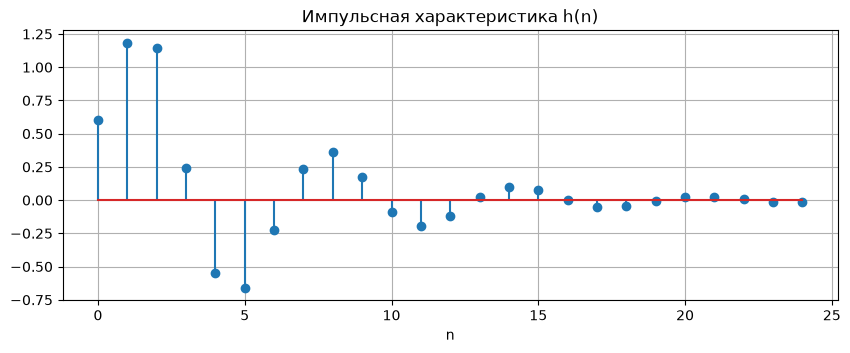

In [18]:
# ИХ - реакция на цифровой единичный импульс
u0 = np.zeros(N1)
u0[0] = 1
h = signal.lfilter(b, a, u0)
print('h(n) =', h)

plt.stem(np.arange(N1), h)
plt.title('Импульсная характеристика h(n)')
plt.xlabel('n')
plt.show()

##### Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий. 

Характеристическое уравнение:

$$ \lambda^2 - 0.9028\lambda + 0.67 = 0, \qquad D = 0.81505 - 2.68 = -1.86495, $$

$$ \lambda_{1,2} = \frac{0.9028 \pm j\,1.36563}{2} = 0.4514 \pm j\,0.6828 = r e^{\pm j\theta}, $$

где $r = \sqrt{0.4514^2 + 0.6828^2} = 0.8185$ - модуль корня, $\theta = \operatorname{arctg}\frac{0.6828}{0.4514} = 0.3141\pi$ - аргумент корня.

При комплексных корнях общее решение имеет вид $r^n(C_1\cos\theta n + C_2\sin\theta n)$. Однородное уравнение $h(n) - 0.9028h(n-1) + 0.67h(n-2) = 0$ выполняется при $n \geqslant 3$, начальными значениями для него служат $h(1)$ и $h(2)$. Поэтому решение записывается с отсчетом от $n = 1$:

$$ h(n) = r^{n-1}\left(C_1\cos\theta(n-1) + C_2\sin\theta(n-1)\right). $$

Постоянные $C_1$ и $C_2$ находятся из системы по $h(1)$ и $h(2)$:

$$ \begin{cases} n = 1: & C_1 = 1.1844 \\ n = 2: & 0.4514\,C_1 + 0.6828\,C_2 = 1.14728 \end{cases} \quad\Rightarrow\quad C_2 = \frac{1.14728 - 0.53464}{0.6828} = 0.8972. $$

Аналитическая формула ИХ:

$$ h(n) = \begin{cases} 0.6, & n = 0 \\ 0.8185^{\,n-1}\left(1.1844\cos(0.3141\pi(n-1)) + 0.8972\sin(0.3141\pi(n-1))\right), & n \geqslant 1 \end{cases} $$

In [19]:
# корни характеристического уравнения
lam = np.roots([1, a1, a2])
r = abs(lam[0])
theta = abs(np.angle(lam[0]))
print(f'r = {r:.4f}, theta = {theta/np.pi:.4f}pi')

# постоянные по h(1) и h(2)
C1 = h[1]
C2 = (h[2] - r * np.cos(theta) * C1) / (r * np.sin(theta))
print(f'C1 = {C1:.4f}, C2 = {C2:.4f}')

n = np.arange(N1)
h_formula = r ** (n - 1) * (C1 * np.cos(theta * (n - 1)) + C2 * np.sin(theta * (n - 1)))
h_formula[0] = b0
print('максимальная разница с lfilter:', np.max(np.abs(h_formula - h)))

r = 0.8185, theta = 0.3141pi
C1 = 1.1844, C2 = 0.8972
максимальная разница с lfilter: 1.1102230246251565e-16


##### Пояснить, чему в действительности равна длина импульсной характеристики.

Длина ИХ бесконечна: множитель $0.8185^{n-1}$ стремится к нулю, но нулю не равен ни при каком $n$. $N_1 = 25$ - только число вычисленных отсчетов.

#### 2. Вычислить реакцию $y_1(n)$ по формуле свёртки. В качестве воздействия $x(n)$ длины $N_2$ выбрать дискретный прямоугольный импульс. Вывести графики воздействия и реакции. Пояснить: чему равна длина импульса $x$; чему равна длина свёртки аналитически и по графику; почему её ограничивают до длины воздействия.

Длина импульса $N_2/2 = 17.5$, после округления 18 отсчетов:

$$ x(n) = \begin{cases}1, & 0 \leqslant n \leqslant 17 \\ 0, & 18 \leqslant n \leqslant 34\end{cases} $$

При $n \leqslant 17$ все $x(n-m)$ в сумме свертки равны единице, и свертка равна накопленной сумме ИХ:

$y_1(0) = h(0) = 0.6$

$y_1(1) = h(0) + h(1) = 0.6 + 1.1844 = 1.7844$

$y_1(2) = h(0) + h(1) + h(2) = 1.7844 + 1.1473 = 2.9317$

длина импульса: 18
длина полной свертки: 59 , N1 + N2 - 1 = 59
последний ненулевой отсчет свертки: n = 41
y1(n) = [ 0.6     1.7844  2.9317  3.1739  2.6239  1.9651  1.7388  1.9759  2.3416
  2.5129  2.4225  2.2261  2.1094  2.1356  2.2374  2.3118  2.3108  2.2599
  1.6148  0.4237 -0.6994 -0.9153 -0.3577  0.2903  0.5018  0.2646 -0.1011
 -0.2723 -0.1819  0.0144  0.1311  0.1049  0.0031 -0.0713 -0.0702]


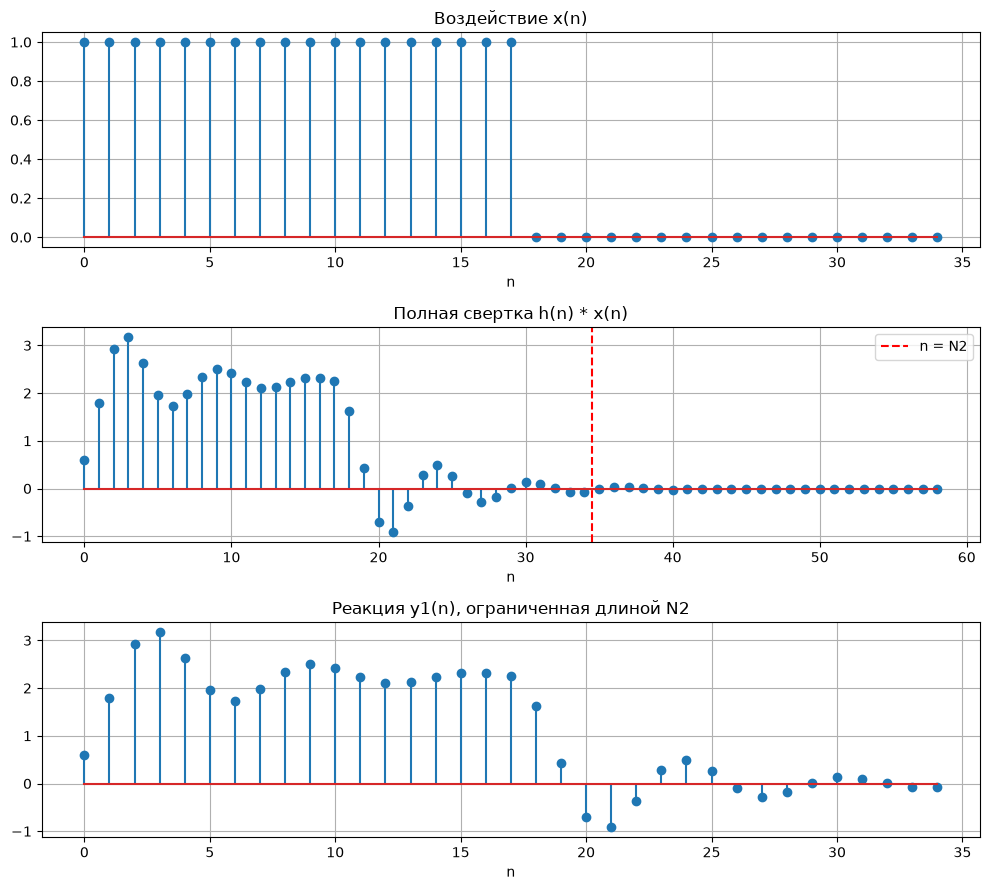

In [20]:
# прямоугольный импульс
L_imp = int(np.floor(N2 / 2 + 0.5))
x = np.zeros(N2)
x[:L_imp] = 1
print('длина импульса:', L_imp)

y_full = np.convolve(h, x)   # полная свертка
y1 = y_full[:N2]             # ограничение длиной воздействия
print('длина полной свертки:', len(y_full), ', N1 + N2 - 1 =', N1 + N2 - 1)
print('последний ненулевой отсчет свертки: n =', np.max(np.nonzero(np.round(y_full, 12))))
print('y1(n) =', y1)

fig, ax = plt.subplots(3, 1, figsize=(10, 9))
ax[0].stem(np.arange(N2), x)
ax[0].set_title('Воздействие x(n)')
ax[1].stem(np.arange(len(y_full)), y_full)
ax[1].axvline(N2 - 0.5, color='r', ls='--', label='n = N2')
ax[1].legend()
ax[1].set_title('Полная свертка h(n) * x(n)')
ax[2].stem(np.arange(N2), y1)
ax[2].set_title('Реакция y1(n), ограниченная длиной N2')
for axis in ax:
    axis.set_xlabel('n')
plt.tight_layout()
plt.show()

Длина импульса $x$ равна 18 отсчетам ($n = 0, \dots, 17$), длина всей последовательности $x(n)$ равна $N_2 = 35$.

Длина свертки аналитически $N_1 + N_2 - 1 = 25 + 35 - 1 = 59$, на графике полная свертка тоже занимает отсчеты с 0 по 58. Ненулевые значения заканчиваются на $n = 17 + 24 = 41$, дальше в сумму попадают только нулевые отсчеты $x$.

Свертку ограничивают длиной воздействия, потому что ИХ взята усеченной до 25 отсчетов и хвост свертки посчитан неточно. Кроме того, реакцию обычно рассматривают на том же интервале, что и воздействие.

#### 3. Вычислить реакцию $y_2(n)$ по разностному уравнению. Задать воздействие $x(n)$ из п. 2. Вывести графики воздействия и реакции. Сравнить графики реакций $y_1(n)$ и $y_2(n)$. Записать разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами. Пояснить, чему равны длины воздействия и реакции.

Разностное уравнение звена:

$$ y(n) = 0.6\,x(n) + 0.64272\,x(n-1) + 0.48\,x(n-2) + 0.9028\,y(n-1) - 0.67\,y(n-2). $$

Начальные условия нулевые: $x(-1) = x(-2) = y(-1) = y(-2) = 0$.

совпадает с lfilter: True
длина воздействия: 35 , длина реакции: 35
|y1 - y2| = [0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
 0.     0.     0.     0.     0.     0.0061 0.0018 0.0063 0.0107 0.0092
 0.0049 0.0021 0.0024 0.0045 0.0063]


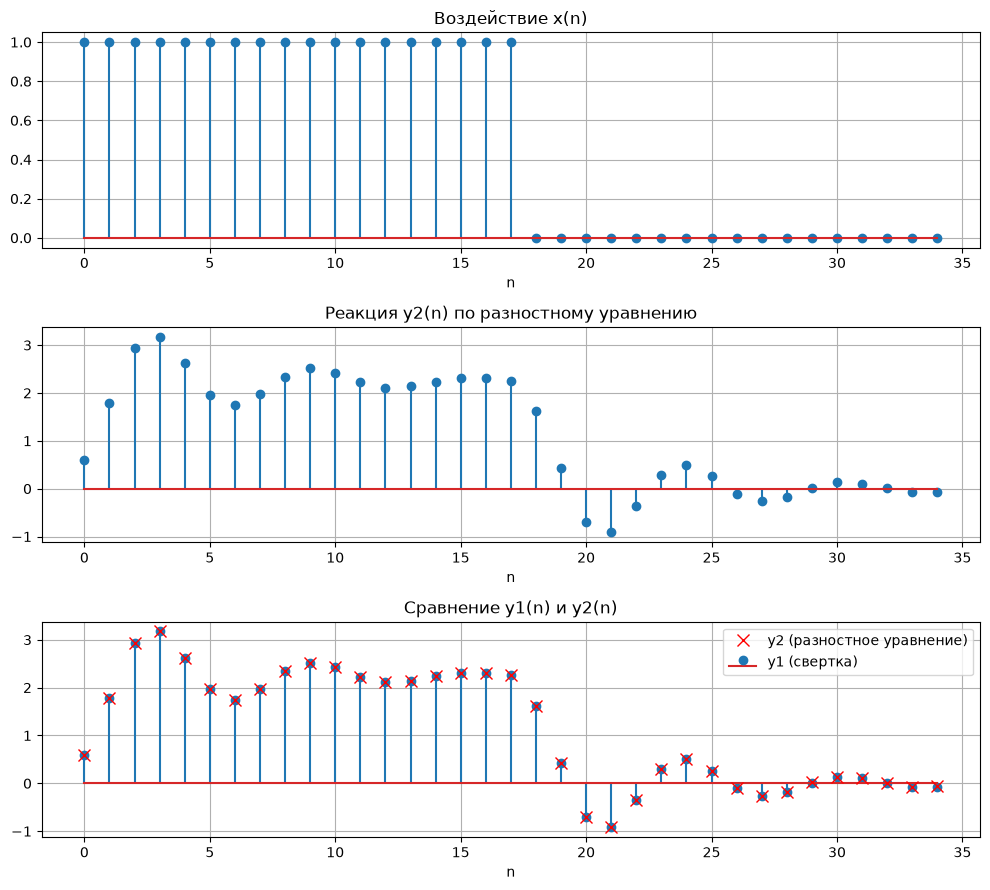

In [21]:
# расчет по разностному уравнению в цикле, начальные условия нулевые
y2 = np.zeros(N2)
for k in range(N2):
    x1 = x[k - 1] if k >= 1 else 0
    x2 = x[k - 2] if k >= 2 else 0
    y_1 = y2[k - 1] if k >= 1 else 0
    y_2 = y2[k - 2] if k >= 2 else 0
    y2[k] = b0 * x[k] + b1 * x1 + b2 * x2 - a1 * y_1 - a2 * y_2

print('совпадает с lfilter:', np.allclose(y2, signal.lfilter(b, a, x)))
print('длина воздействия:', len(x), ', длина реакции:', len(y2))
print('|y1 - y2| =', np.abs(y1 - y2))

fig, ax = plt.subplots(3, 1, figsize=(10, 9))
ax[0].stem(np.arange(N2), x)
ax[0].set_title('Воздействие x(n)')
ax[1].stem(np.arange(N2), y2)
ax[1].set_title('Реакция y2(n) по разностному уравнению')
ax[2].stem(np.arange(N2), y1, label='y1 (свертка)')
ax[2].plot(np.arange(N2), y2, 'rx', ms=9, label='y2 (разностное уравнение)')
ax[2].legend()
ax[2].set_title('Сравнение y1(n) и y2(n)')
for axis in ax:
    axis.set_xlabel('n')
plt.tight_layout()
plt.show()

Графики $y_1(n)$ и $y_2(n)$ совпадают. При $n \leqslant 24$ разница нулевая, начиная с $n = 25$ появляется расхождение до $0.011$: в свертке использованы только 25 отсчетов ИХ, а разностное уравнение учитывает всю ИХ.

Длина воздействия и длина реакции равны 35 отсчетам. Теоретически реакция рекурсивного звена бесконечна, как и ИХ.

#### 4. Вычислить нули и полюсы передаточной функции. Записать нули и полюсы в алгебраической и показательной формах и пояснить связь между ними. Выразить значение аргумента полюса и нуля относительно π. Представить передаточную функцию в виде произведения простейших множителей с нулями и полюсами в показательной форме.

После умножения числителя и знаменателя на $z^2$:

$$ H(z) = \frac{0.6 z^2 + 0.64272 z + 0.48}{z^2 - 0.9028 z + 0.67}. $$

Знаменатель совпадает с характеристическим уравнением из п. 1, поэтому полюсы $z_{*1,2} = 0.4514 \pm j\,0.6828$, $|z_*| = 0.8185$, $\arg z_{*1} = \operatorname{arctg}\frac{0.6828}{0.4514} = 0.9867$ рад.

Нули - корни уравнения $0.6 z^2 + 0.64272 z + 0.48 = 0$:

$$ D = 0.41309 - 1.152 = -0.73891, \qquad z_{01,2} = \frac{-0.64272 \pm j\,0.85960}{1.2} = -0.5356 \pm j\,0.7163. $$

$|z_0| = \sqrt{0.5356^2 + 0.7163^2} = 0.8944$. Нуль $z_{01}$ лежит во второй четверти, поэтому

$\arg z_{01} = \pi - \operatorname{arctg}\frac{0.7163}{0.5356} = 3.14159 - 0.92875 = 2.2128$ рад

In [22]:
zeros = np.roots(b)
poles = np.roots(a)

print('Нули:')
for q in zeros:
    print(f'  {q.real:+.4f} {q.imag:+.4f}j  =  {abs(q):.4f} * exp(j * {np.angle(q)/np.pi:+.4f}pi)')
print('Полюсы:')
for q in poles:
    print(f'  {q.real:+.4f} {q.imag:+.4f}j  =  {abs(q):.4f} * exp(j * {np.angle(q)/np.pi:+.4f}pi)')

Нули:
  -0.5356 +0.7163j  =  0.8944 * exp(j * +0.7044pi)
  -0.5356 -0.7163j  =  0.8944 * exp(j * -0.7044pi)
Полюсы:
  +0.4514 +0.6828j  =  0.8185 * exp(j * +0.3141pi)
  +0.4514 -0.6828j  =  0.8185 * exp(j * -0.3141pi)


| | Алгебраическая форма | Показательная форма |
|---|---|---|
| $z_{01,2}$ | $-0.5356 \pm j\,0.7163$ | $0.8944\, e^{\pm j\,0.7044\pi}$ |
| $z_{*1,2}$ | $0.4514 \pm j\,0.6828$ | $0.8185\, e^{\pm j\,0.3141\pi}$ |

Связь между формами. Алгебраическая и показательная формы - две записи одного числа: $x + jy = r e^{j\varphi}$, где $r = \sqrt{x^2 + y^2}$, $\varphi = \operatorname{arctg}(y/x)$ с учетом четверти. Обратный переход: $x = r\cos\varphi$, $y = r\sin\varphi$.

Аргументы относительно $\pi$: у полюса $0.9867 / 3.1416 = 0.3141$, то есть $\pm 0.3141\pi$; у нуля $2.2128 / 3.1416 = 0.7044$, то есть $\pm 0.7044\pi$.

Передаточная функция в виде произведения простейших множителей:

$$ H(z) = 0.6\,\frac{\left(1 - 0.8944\,e^{j0.7044\pi} z^{-1}\right)\left(1 - 0.8944\,e^{-j0.7044\pi} z^{-1}\right)}{\left(1 - 0.8185\,e^{j0.3141\pi} z^{-1}\right)\left(1 - 0.8185\,e^{-j0.3141\pi} z^{-1}\right)}. $$

#### 5. Изобразить карту нулей и полюсов. Пояснить: является ли рекурсивное звено устойчивым; совпадают ли значения нулей и полюсов с вычисленными в п. 4.

нули: [-0.5356+0.7163j -0.5356-0.7163j]
полюсы: [0.4514+0.6828j 0.4514-0.6828j]
коэффициент k = 0.6
совпадают с п. 4: True True
модули полюсов: [0.8185 0.8185]


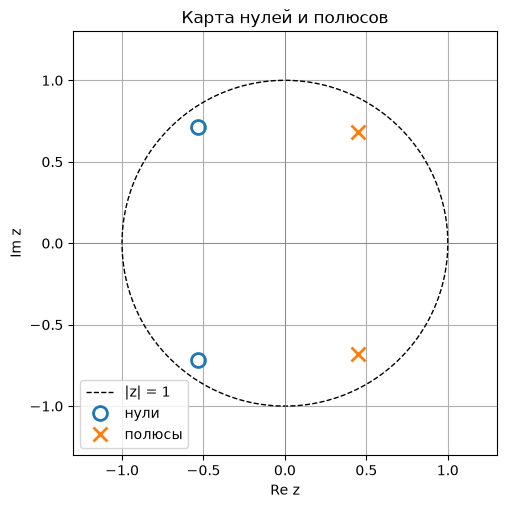

In [23]:
# нули и полюсы другой функцией, для проверки
z_m, p_m, k_m = signal.tf2zpk(b, a)
print('нули:', z_m)
print('полюсы:', p_m)
print('коэффициент k =', k_m)
print('совпадают с п. 4:', np.allclose(np.sort_complex(z_m), np.sort_complex(zeros)),
      np.allclose(np.sort_complex(p_m), np.sort_complex(poles)))
print('модули полюсов:', np.abs(p_m))

t = np.linspace(0, 2 * np.pi, 400)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(np.cos(t), np.sin(t), 'k--', lw=1, label='|z| = 1')
ax.plot(z_m.real, z_m.imag, 'o', mfc='none', ms=10, mew=2, label='нули')
ax.plot(p_m.real, p_m.imag, 'x', ms=10, mew=2, label='полюсы')
ax.axhline(0, color='gray', lw=0.5)
ax.axvline(0, color='gray', lw=0.5)
ax.set_aspect('equal')
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_xlabel('Re z')
ax.set_ylabel('Im z')
ax.set_title('Карта нулей и полюсов')
ax.legend(loc='lower left')
plt.show()

Оба полюса лежат внутри единичной окружности ($|z_*| = 0.8185 < 1$), значит звено устойчиво.

Нули и полюсы, найденные функцией `tf2zpk`, совпадают с вычисленными в п. 4.

#### 6. Вычислить амплитудно-частотную (АЧХ) и фазочастотную (ФЧХ) характеристики в шкале нормированных частот $\hat\omega$ и вывести их графики. Пояснить: чему равны границы основной полосы частот; соответствие между картой нулей и полюсов и видом АЧХ; какому значению АЧХ соответствует скачок на π, если он имеется; какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции.

После подстановки $z = e^{j\hat\omega}$:

$$ H(e^{j\hat\omega}) = \frac{0.6 + 0.64272 e^{-j\hat\omega} + 0.48 e^{-j2\hat\omega}}{1 - 0.9028 e^{-j\hat\omega} + 0.67 e^{-j2\hat\omega}}. $$

По формуле Эйлера $e^{-jk\hat\omega} = \cos k\hat\omega - j\sin k\hat\omega$ вещественные и мнимые части числителя и знаменателя:

$\operatorname{Re}_b = 0.6 + 0.64272\cos\hat\omega + 0.48\cos 2\hat\omega$, $\quad \operatorname{Im}_b = -0.64272\sin\hat\omega - 0.48\sin 2\hat\omega$

$\operatorname{Re}_a = 1 - 0.9028\cos\hat\omega + 0.67\cos 2\hat\omega$, $\quad \operatorname{Im}_a = 0.9028\sin\hat\omega - 0.67\sin 2\hat\omega$

$$ A(\hat\omega) = \frac{\sqrt{\operatorname{Re}_b^2 + \operatorname{Im}_b^2}}{\sqrt{\operatorname{Re}_a^2 + \operatorname{Im}_a^2}}, \qquad \Phi(\hat\omega) = \operatorname{arctg}\frac{\operatorname{Im}_b}{\operatorname{Re}_b} - \operatorname{arctg}\frac{\operatorname{Im}_a}{\operatorname{Re}_a}. $$

Вещественные части $\operatorname{Re}_b$ и $\operatorname{Re}_a$ на $[0, \pi]$ положительны, поэтому поправка на четверть не нужна.

разница с freqz: АЧХ 5.329070518200751e-15  ФЧХ 1.3322676295501878e-15
A(0) = 2.2455
A(pi) = 0.1700
максимум A = 4.6028 при w = 0.3004pi
минимум A = 0.0497 при w = 0.7084pi
ФЧХ меняется от -2.6248 до 0.0000 рад
скачки ФЧХ больше pi: []


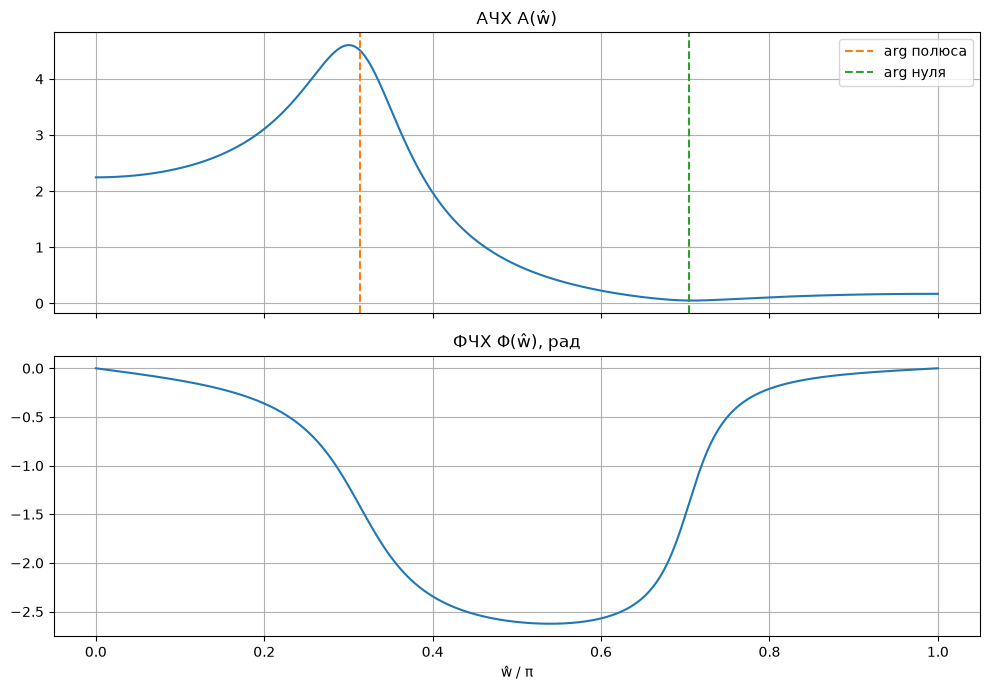

In [24]:
def freq_resp(w):
    # вещественные и мнимые части числителя и знаменателя при z = e^{jw}
    re_n = b0 + b1 * np.cos(w) + b2 * np.cos(2 * w)
    im_n = -(b1 * np.sin(w) + b2 * np.sin(2 * w))
    re_d = 1 + a1 * np.cos(w) + a2 * np.cos(2 * w)
    im_d = -(a1 * np.sin(w) + a2 * np.sin(2 * w))
    A = np.sqrt(re_n**2 + im_n**2) / np.sqrt(re_d**2 + im_d**2)
    phi = np.arctan(im_n / re_n) - np.arctan(im_d / re_d)
    return A, phi

w = np.linspace(0, np.pi, 4096)
A, phi = freq_resp(w)

# проверка готовой функцией
_, H = signal.freqz(b, a, worN=w)
print('разница с freqz: АЧХ', np.max(np.abs(A - np.abs(H))), ' ФЧХ', np.max(np.abs(phi - np.angle(H))))

i_max = np.argmax(A)
i_min = np.argmin(A)
print(f'A(0) = {A[0]:.4f}')
print(f'A(pi) = {A[-1]:.4f}')
print(f'максимум A = {A[i_max]:.4f} при w = {w[i_max]/np.pi:.4f}pi')
print(f'минимум A = {A[i_min]:.4f} при w = {w[i_min]/np.pi:.4f}pi')
print(f'ФЧХ меняется от {phi.min():.4f} до {phi.max():.4f} рад')
print('скачки ФЧХ больше pi:', w[np.where(np.abs(np.diff(phi)) > np.pi)[0]] / np.pi)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(w / np.pi, A)
ax[0].axvline(np.angle(poles[poles.imag > 0][0]) / np.pi, color='C1', ls='--', label='arg полюса')
ax[0].axvline(np.angle(zeros[zeros.imag > 0][0]) / np.pi, color='C2', ls='--', label='arg нуля')
ax[0].legend()
ax[0].set_title('АЧХ A(ŵ)')
ax[1].plot(w / np.pi, phi)
ax[1].set_title('ФЧХ Φ(ŵ), рад')
ax[1].set_xlabel('ŵ / π')
plt.tight_layout()
plt.show()

Основная полоса частот $\hat\omega \in [0, \pi]$.

АЧХ определяется расстояниями от точки $e^{j\hat\omega}$ на единичной окружности до нулей и полюсов. Около аргумента полюса $0.314\pi$ АЧХ имеет максимум $4.60$ (на $0.300\pi$), около аргумента нуля $0.704\pi$ минимум $0.050$ (на $0.708\pi$). Нуль не лежит на окружности, поэтому АЧХ в ноль не обращается.

Скачок ФЧХ на $\pi$ соответствует нулевому значению АЧХ. Здесь АЧХ нигде не равна нулю, скачка нет.

Преимущественно подавлены высокие частоты: от $0.6\pi$ до $\pi$ АЧХ меньше $0.3$.

#### 7. Вычислить АЧХ и ФЧХ в шкале частот $f$ (Гц) при заданной частоте дискретизации $f_d$ и вывести их графики. Пояснить: чему равны границы основной полосы частот; соответствие между частотами $\hat\omega$ и $f$.

Связь частот: $f = \dfrac{\hat\omega f_d}{2\pi} = \dfrac{\hat\omega}{\pi} \cdot \dfrac{f_d}{2} = \dfrac{\hat\omega}{\pi} \cdot 2500$ Гц.

АЧХ и ФЧХ вычисляются по формулам п. 6 при $\hat\omega = 2\pi f / f_d$.

основная полоса: от 0 до 2500.0 Гц
максимум АЧХ при f = 750.9 Гц
минимум АЧХ при f = 1771.1 Гц


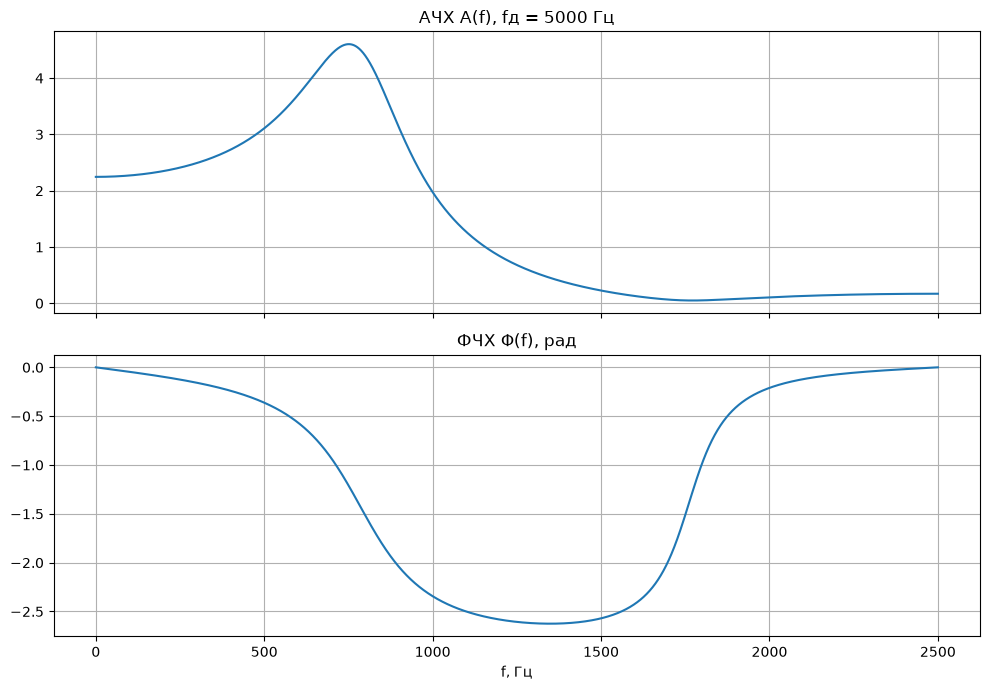

In [25]:
f = np.linspace(0, fd1 / 2, 4096)   # f от 0 до fd/2
Af, phif = freq_resp(2 * np.pi * f / fd1)
print('основная полоса: от 0 до', fd1 / 2, 'Гц')
print(f'максимум АЧХ при f = {f[np.argmax(Af)]:.1f} Гц')
print(f'минимум АЧХ при f = {f[np.argmin(Af)]:.1f} Гц')

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(f, Af)
ax[0].set_title(f'АЧХ A(f), fд = {fd1} Гц')
ax[1].plot(f, phif)
ax[1].set_title('ФЧХ Φ(f), рад')
ax[1].set_xlabel('f, Гц')
plt.tight_layout()
plt.show()

Основная полоса частот от $0$ до $f_d/2 = 2500$ Гц.

Соответствие частот:

| $\hat\omega$ | $f$, Гц |
|---|---|
| $0$ | $0$ |
| $0.3004\pi$ (максимум) | $0.3004 \cdot 2500 \approx 751$ |
| $0.7084\pi$ (минимум) | $0.7084 \cdot 2500 \approx 1771$ |
| $\pi$ | $2500$ |

### Часть 2

#### Исходные данные

$N = 64$

$f_d = 2000 \cdot (5 \bmod 5 + 1) = 2000$ Гц, $T = 1/f_d = 0.0005$ с $= 0.5$ мс

$A_1 = 1 + 0.01 \cdot 5 = 1.05$, $A_2 = 2A_1 = 2.1$

$f_1 = f_d / 8 = 250$ Гц, $f_2 = 1.5 f_1 = 375$ Гц

$$ x(nT) = 1.05\cos(2\pi \cdot 250\, nT + \pi/4) + 2.1\cos(2\pi \cdot 375\, nT + \pi/8). $$

После подстановки $T = 1/2000$:

$$ x(n) = 1.05\cos\left(\frac{\pi}{4} n + \frac{\pi}{4}\right) + 2.1\cos\left(\frac{3\pi}{8} n + \frac{\pi}{8}\right). $$

Первая гармоника повторяется через 8 отсчетов, вторая через 16, значит сумма периодична с периодом 16. На $N = 64$ укладывается ровно 8 периодов первой гармоники и 12 периодов второй, так что $N = 64$ тоже период последовательности.

In [26]:
N = 64
fd = 2000 * (Nvar % 5 + 1)
T = 1 / fd
A1 = 1 + 0.01 * Nvar
A2 = 2 * A1
f1 = fd / 8
f2 = 1.5 * f1
print(f'N = {N}, fd = {fd} Гц, T = {T} с')
print(f'A1 = {A1}, A2 = {A2}, f1 = {f1} Гц, f2 = {f2} Гц')

def x_analog(t):
    return A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8)

N = 64, fd = 2000 Гц, T = 0.0005 с
A1 = 1.05, A2 = 2.1, f1 = 250.0 Гц, f2 = 375.0 Гц


#### 1. Вывести графики последовательности $x(n)$ на периоде $N$ в шкале дискретного и дискретного нормированного времени.

x(0..3) = [ 2.6826  0.     -2.6826 -2.5349]


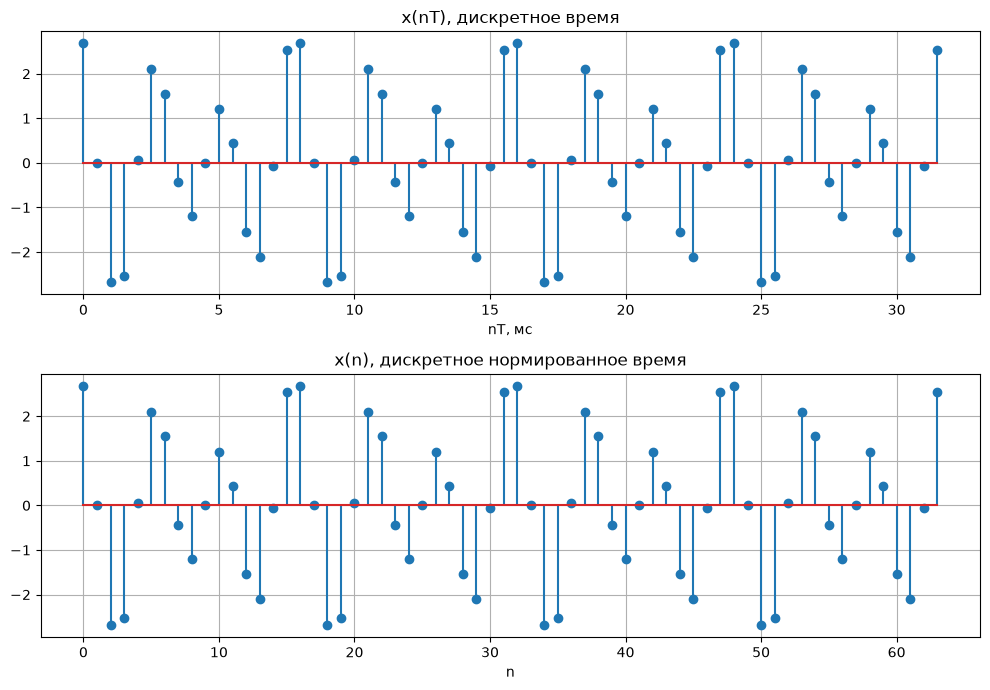

In [27]:
n = np.arange(N)
xn = x_analog(n * T)
print('x(0..3) =', xn[:4])

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].stem(n * T * 1000, xn)
ax[0].set_title('x(nT), дискретное время')
ax[0].set_xlabel('nT, мс')
ax[1].stem(n, xn)
ax[1].set_title('x(n), дискретное нормированное время')
ax[1].set_xlabel('n')
plt.tight_layout()
plt.show()

#### 2. Вычислить ОДПФ от ДПФ последовательности $x(n)$ и вывести график полученной последовательности в шкале дискретного нормированного времени.

максимальная мнимая часть: 1.1102230246251625e-16
максимальная разница с x(n): 6.106226635438361e-16


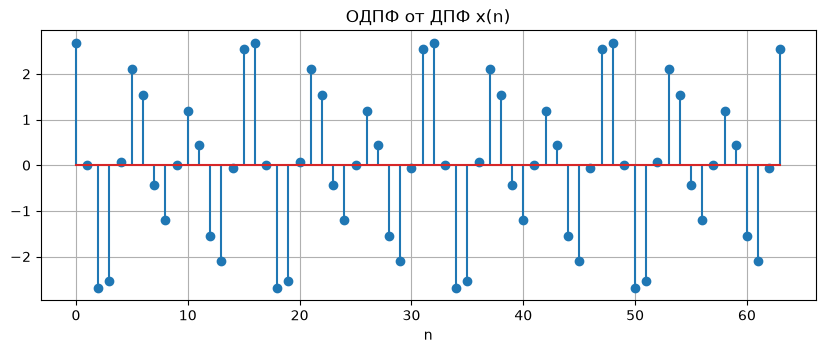

In [28]:
X = np.fft.fft(xn)
x_back = np.fft.ifft(X)
print('максимальная мнимая часть:', np.max(np.abs(x_back.imag)))
print('максимальная разница с x(n):', np.max(np.abs(x_back.real - xn)))

plt.stem(n, x_back.real)
plt.title('ОДПФ от ДПФ x(n)')
plt.xlabel('n')
plt.show()

ОДПФ от ДПФ восстанавливает исходную последовательность: расхождение с $x(n)$ порядка $10^{-16}$, на уровне ошибок округления.

#### 3. Вычислить амплитудный и фазовый спектры последовательности $x(n)$ и вывести их графики в шкалах дискретных нормированных и абсолютных частот. Пояснить: связь дискретного нормированного времени с дискретным временем; связь частоты $f$ (Гц) с дискретной нормированной частотой; вид амплитудного и фазового спектров.

Номера отсчетов гармоник $k = f N / f_d$: $k_1 = 250 \cdot 64 / 2000 = 8$, $k_2 = 375 \cdot 64 / 2000 = 12$.

k1 = 8.0 , k2 = 12.0
k =  8, f =  250.00 Гц, X = 23.76+23.76j, |X|/N = 0.5250, arg X = +0.2500pi
k = 12, f =  375.00 Гц, X = 62.08+25.72j, |X|/N = 1.0500, arg X = +0.1250pi
k = 52, f = 1625.00 Гц, X = 62.08-25.72j, |X|/N = 1.0500, arg X = -0.1250pi
k = 56, f = 1750.00 Гц, X = 23.76-23.76j, |X|/N = 0.5250, arg X = -0.2500pi


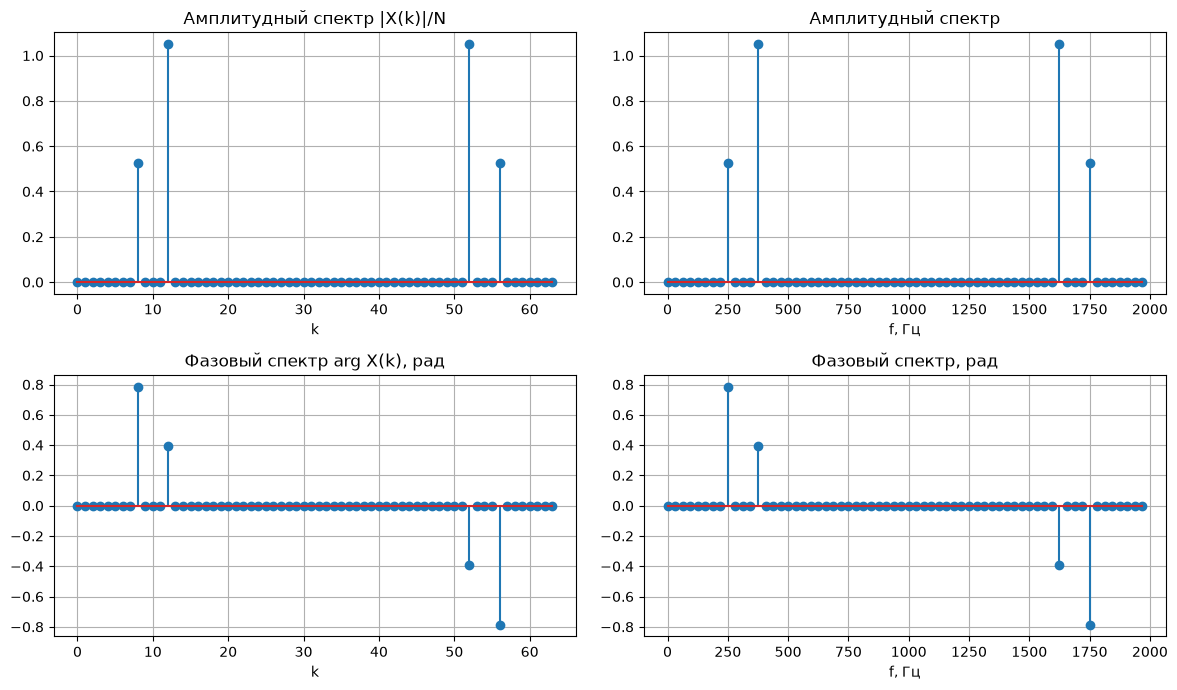

In [29]:
print('k1 =', f1 * N / fd, ', k2 =', f2 * N / fd)

k = np.arange(N)
amp = np.abs(X) / N
ph = np.angle(X)
# там, где |X| практически ноль, фаза - шум округления, она обнуляется
ph[np.abs(X) < 1e-9 * np.abs(X).max()] = 0

for kk in np.where(amp > 1e-9)[0]:
    print(f'k = {kk:2d}, f = {kk * fd / N:7.2f} Гц, X = {X[kk]:.2f}, |X|/N = {amp[kk]:.4f}, arg X = {ph[kk]/np.pi:+.4f}pi')

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].stem(k, amp)
ax[0, 0].set_title('Амплитудный спектр |X(k)|/N')
ax[0, 0].set_xlabel('k')
ax[1, 0].stem(k, ph)
ax[1, 0].set_title('Фазовый спектр arg X(k), рад')
ax[1, 0].set_xlabel('k')
ax[0, 1].stem(k * fd / N, amp)
ax[0, 1].set_title('Амплитудный спектр')
ax[0, 1].set_xlabel('f, Гц')
ax[1, 1].stem(k * fd / N, ph)
ax[1, 1].set_title('Фазовый спектр, рад')
ax[1, 1].set_xlabel('f, Гц')
plt.tight_layout()
plt.show()

Дискретное нормированное время связано с дискретным: $n = nT / T$, $T = 0.5$ мс.

Частота отсчета ДПФ $f = k f_d / N = 31.25 k$ Гц, нормированная частота $\hat\omega = 2\pi f / f_d = 2\pi k / N$.

Амплитудный спектр состоит из четырех линий: $k = 8$ и $k = 12$ (250 и 375 Гц) и симметричные им $k = 56$ и $k = 52$, соответствующие отрицательным частотам, если так можно сказать. Амплитуда каждой линии равна половине амплитуды гармоники: $0.525$ и $1.05$.

Фазовый спектр нечетный: на линиях фаза равна начальной фазе гармоники, $\pm\pi/4$ и $\pm\pi/8$. На остальных отсчетах амплитуда нулевая, фаза принята равной нулю.

#### 4. Вычислить ДПФ конечной последовательности $x(n)$ длины $N$. Вывести графики в шкале дискретных нормированных частот модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности. Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.

|X(k)| на ненулевых отсчетах: [33.6 67.2 67.2 33.6]
|X(k)|/N:                      [0.525 1.05  1.05  0.525]
отношение: [64. 64. 64. 64.]


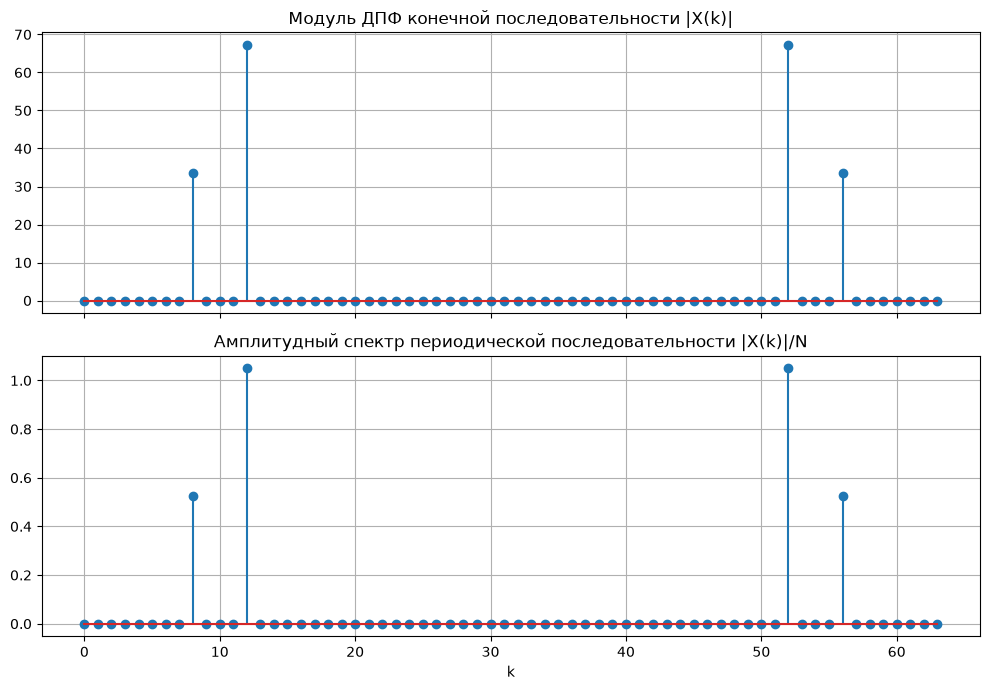

In [30]:
X_fin = np.fft.fft(xn, N)
nz = np.where(amp > 1e-9)[0]
print('|X(k)| на ненулевых отсчетах:', np.abs(X_fin)[nz])
print('|X(k)|/N:                     ', amp[nz])
print('отношение:', np.abs(X_fin)[nz] / amp[nz])

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].stem(k, np.abs(X_fin))
ax[0].set_title('Модуль ДПФ конечной последовательности |X(k)|')
ax[1].stem(k, amp)
ax[1].set_title('Амплитудный спектр периодической последовательности |X(k)|/N')
ax[1].set_xlabel('k')
plt.tight_layout()
plt.show()

Графики по форме одинаковые, отличаются только масштабом по вертикали: модуль ДПФ конечной последовательности в $N = 64$ раза больше амплитудного спектра периодической. Так получается потому, что амплитудный спектр периодической последовательности по определению нормирован на $N$.

#### 5. Восстановить периодический аналоговый сигнал $x(t)$ по отсчётам ДПФ $X(k)$ периодической последовательности $x(n)$.

Сигнал восстанавливается по формуле из теоретических положений на сетке с шагом $T/4$.

число точек по времени: 253
максимальная мнимая часть x(t): 1.0719825563744738e-15
максимальная разница с исходным сигналом: 2.1538326677728037e-14


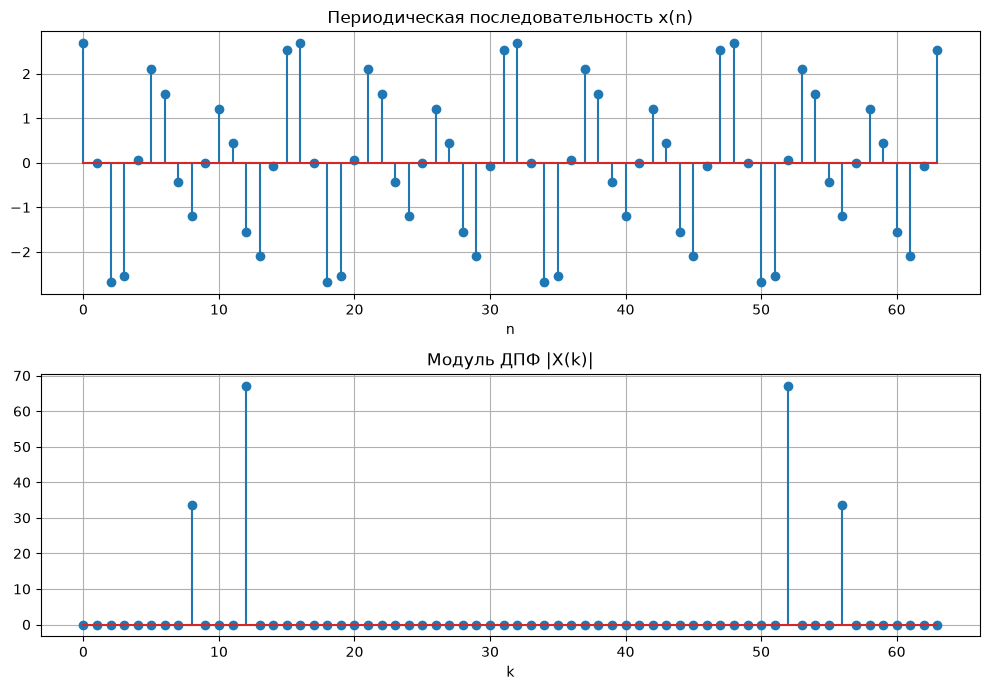

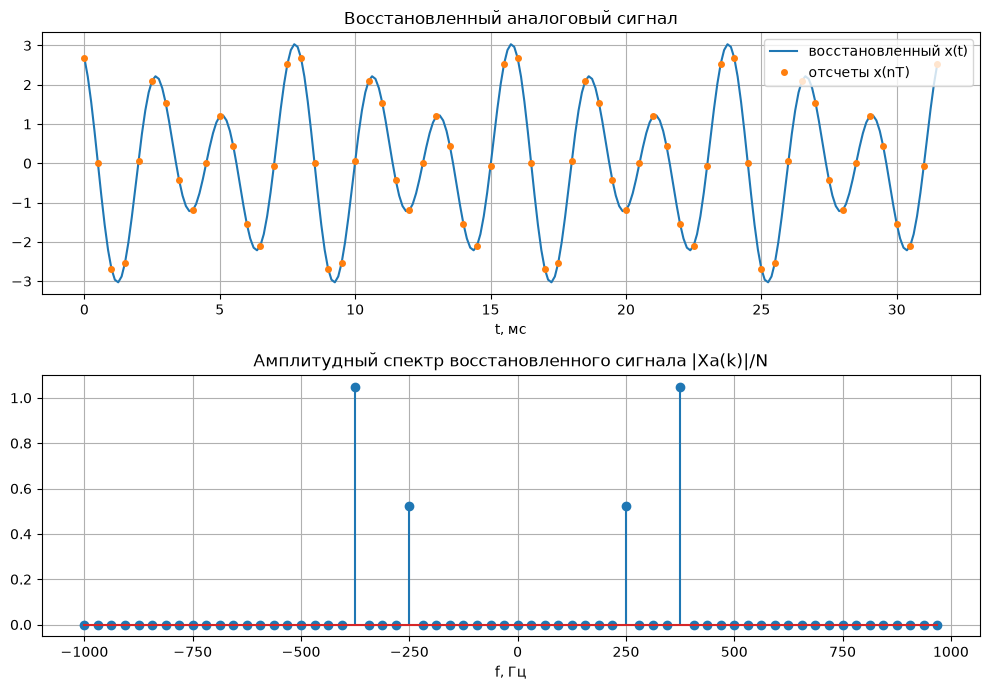

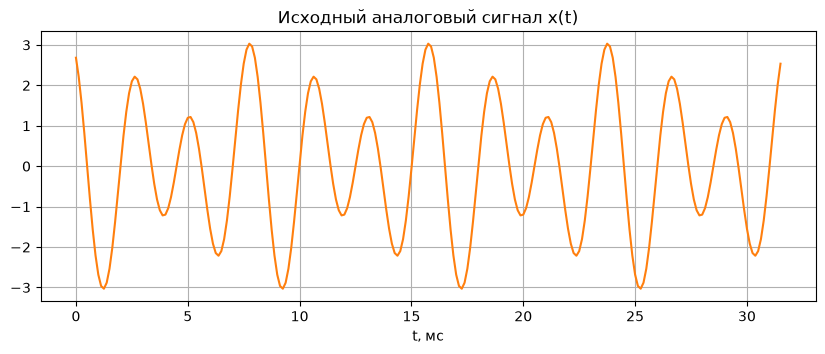

In [31]:
# X_a(k) для k = -N/2 ... N/2-1
ka = np.arange(-N // 2, N // 2)
Xa = X[ka % N]   # при k < 0 берется X(N + k)

dt = 0.25 * T
t = np.arange(0, (N - 1) * T + dt / 2, dt)
print('число точек по времени:', len(t))

# x(t) = 1/N * sum Xa(k) * exp(j*2*pi*k*t/(N*T))
x_t = np.zeros(len(t), dtype=complex)
for i in range(N):
    x_t += Xa[i] * np.exp(1j * 2 * np.pi / (N * T) * ka[i] * t)
x_t /= N

print('максимальная мнимая часть x(t):', np.max(np.abs(x_t.imag)))
print('максимальная разница с исходным сигналом:', np.max(np.abs(x_t.real - x_analog(t))))

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].stem(n, xn)
ax[0].set_title('Периодическая последовательность x(n)')
ax[0].set_xlabel('n')
ax[1].stem(k, np.abs(X))
ax[1].set_title('Модуль ДПФ |X(k)|')
ax[1].set_xlabel('k')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(t * 1000, x_t.real, label='восстановленный x(t)')
ax[0].plot(n * T * 1000, xn, 'o', ms=4, label='отсчеты x(nT)')
ax[0].legend()
ax[0].set_title('Восстановленный аналоговый сигнал')
ax[0].set_xlabel('t, мс')
ax[1].stem(ka / (N * T), np.abs(Xa) / N)
ax[1].set_title('Амплитудный спектр восстановленного сигнала |Xa(k)|/N')
ax[1].set_xlabel('f, Гц')
plt.tight_layout()
plt.show()

plt.plot(t * 1000, x_analog(t), 'C1')
plt.title('Исходный аналоговый сигнал x(t)')
plt.xlabel('t, мс')
plt.show()

#### 6. Исходя из результатов п. 5, объяснить: связь модуля ДПФ последовательности со спектром аналогового сигнала; результат визуального сравнения восстановленного и исходного сигналов.


Исходный сигнал периодический с периодом $NT = 32$ мс, его спектр линейчатый: линии на частотах $\pm 250$ и $\pm 375$ Гц с амплитудами $A_1/2 = 0.525$ и $A_2/2 = 1.05$. Обе частоты меньше $f_d/2 = 1000$ Гц, поэтому наложения спектров нет. Модуль ДПФ, деленный на $N$, совпадает с амплитудным спектром аналогового сигнала в полосе от $-f_d/2$ до $f_d/2$, если отсчеты с $k \geqslant N/2$ отнести к отрицательным частотам, как в $X_a(k)$.

Восстановленный и исходный сигналы визуально совпадают, расхождение порядка $10^{-14}$. Восстановление точное, так как спектр сигнала ограничен частотой $f_d/2$, а частоты гармоник попадают точно на отсчеты ДПФ.

#### 7. Проверить равенство Парсеваля. Пояснить его смысл.

In [32]:
E_time = np.sum(np.abs(xn) ** 2)
E_freq = np.sum(np.abs(X) ** 2) / N
print('сумма |x(n)|^2      =', round(E_time, 6))
print('1/N * сумма |X(k)|^2 =', round(E_freq, 6))
print('N*(A1^2 + A2^2)/2   =', round(N * (A1 ** 2 + A2 ** 2) / 2, 6))

сумма |x(n)|^2      = 176.4
1/N * сумма |X(k)|^2 = 176.4
N*(A1^2 + A2^2)/2   = 176.4


Все три значения равны $176.4$, равенство Парсеваля выполняется. Смысл равенства: энергия сигнала, вычисленная по отсчетам во времени и по спектру, одинакова.

## Выводы

Для рекурсивного звена 2-го порядка вычислена ИХ и получена ее аналитическая формула, ИХ бесконечна и затухает. Реакции на прямоугольный импульс, найденные сверткой и по разностному уравнению, совпадают до $n = 24$, дальше расхождение до $0.011$ из-за усечения ИХ.

Нули $0.8944e^{\pm j0.7044\pi}$, полюсы $0.8185e^{\pm j0.3141\pi}$, звено устойчиво. АЧХ имеет максимум $4.60$ на 751 Гц и минимум $0.050$ на 1771 Гц, звено подавляет высокие частоты.

Для суммы двух гармоник ДПФ дает четыре спектральные линии с амплитудами $A/2$ и фазами, равными начальным фазам гармоник. ОДПФ и восстановление аналогового сигнала выполняются без искажений, равенство Парсеваля выполняется.

Сложность вызвала аналитическая формула ИХ: при $b_2 \ne 0$ значение $h(0)$ не подходит под общее решение, поэтому решение записано со сдвигом на единицу, а постоянные найдены по $h(1)$ и $h(2)$.